# 🏭 Production Line Digital Twin — Part 5: Predictive Maintenance (ML)
**Goal:** predict whether a machine will **break down within the next 30 minutes**, using only its sensors
(temperature & vibration).
- Labels come from the failure log
- Time-based train/test split (train on the past, test on the future)
- Models: Logistic Regression vs Random Forest
- Evaluation: recall, precision, confusion matrix, **minutes of early warning**

### Imports
scikit-learn for the models, scaling and metrics. `joblib` saves the trained model.

In [17]:
import os
import joblib                      # to save the trained model to a file
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, recall_score, precision_score)

### Settings and data
- `HORIZON = 30`: predict a failure up to 30 min ahead.
- `WINDOW = 10`: size of the rolling average.
- `ALARM_THRESHOLD = 0.5`: raise an alarm when the predicted risk is ≥ 50%.

In [18]:
HORIZON = 30             # predict failures up to 30 minutes ahead
WINDOW = 10              # rolling average over the last 10 readings
ALARM_THRESHOLD = 0.5    # raise an alarm when predicted risk >= 50%

sensors  = pd.read_csv("../data/sensor_log.csv")
failures = pd.read_csv("../data/failure_log.csv")

print(f"Sensor readings: {len(sensors)}")
print(f"Failures:        {len(failures)}")
sensors.head()

Sensor readings: 19200
Failures:        53


,time,station,status,health,temperature,vibration
0,0,Cutting,idle,100.0,45.79,0.306
1,0,Welding,idle,100.0,45.27,0.381
2,0,Painting,idle,100.0,44.06,0.205
3,0,Inspection,idle,100.0,45.89,0.327
4,1,Cutting,idle,100.0,45.69,0.307


### Create the labels
A reading is labelled **1 ("fails soon")** if the same station breaks within the next 30 min:

$$\text{fail\_soon} = 1 \iff t_{fail} - 30 \le t < t_{fail}$$

All other readings are 0.

In [19]:
# Start by marking every reading as 0 = "no failure soon"
sensors["fail_soon"] = 0

# For each failure, mark the 30 minutes BEFORE it (on that station) as 1 = "fails soon"
for _, f in failures.iterrows():
    in_window = (
        (sensors["station"] == f["station"])
        & (sensors["time"] >= f["failure_time"] - HORIZON)
        & (sensors["time"] <  f["failure_time"])
    )
    sensors.loc[in_window, "fail_soon"] = 1

print(sensors["fail_soon"].value_counts())

fail_soon
0    17610
1     1590
Name: count, dtype: int64


### Keep only running readings
Idle and broken readings follow different formulas (see Part 2), so the model only uses readings taken while a machine is running.

Only a small share of rows are 1, so the classes are **imbalanced**. A model that always says "no failure" would look accurate but be useless.

In [20]:
# Sensor values mean different things when a machine is idle or broken.
# We only predict while the machine is RUNNING, so we keep just those rows.
data = sensors[sensors["status"] == "running"].copy()
data = data.sort_values(["station", "time"]).reset_index(drop=True)

print(f"Running readings: {len(data)}")
print(f"Share of 'fails soon' rows: {data['fail_soon'].mean():.1%}  ← imbalanced!")

Running readings: 14330
Share of 'fails soon' rows: 8.9%  ← imbalanced!


### Do sensors look different before a failure?
First compare the group means. Then plot histograms with `density=True`, which scales each group so its bars' total area is 1. That way the small "fails soon" group can be compared with the large normal group.

           temperature  vibration  health
fail_soon                                
0                72.26       2.66   70.97
1                78.72       3.70   45.13


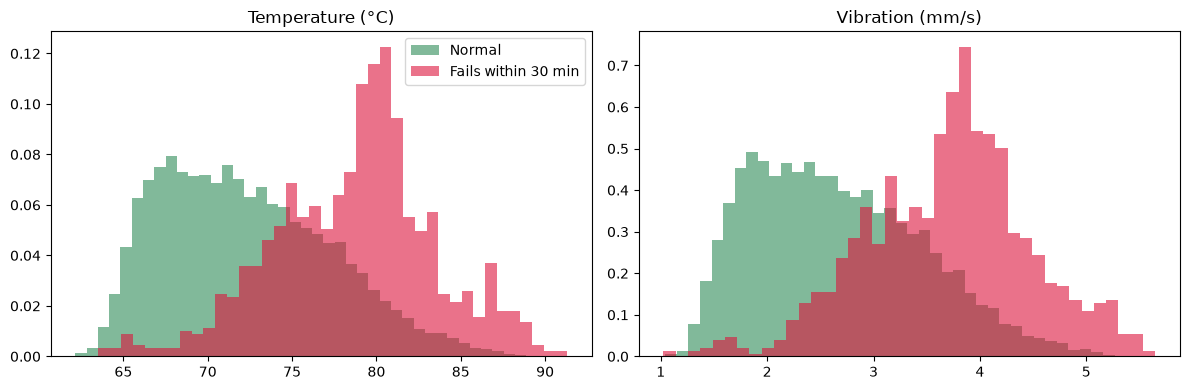

In [21]:
# Average values: normal vs "fails within 30 min"
print(data.groupby("fail_soon")[["temperature", "vibration", "health"]].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color, name in [(0, "seagreen", "Normal"), (1, "crimson", "Fails within 30 min")]:
    subset = data[data["fail_soon"] == label]
    # density=True rescales both groups so we can compare shapes even though group 1 is much smaller
    axes[0].hist(subset["temperature"], bins=40, alpha=0.6, color=color, label=name, density=True)
    axes[1].hist(subset["vibration"],   bins=40, alpha=0.6, color=color, label=name, density=True)

axes[0].set_title("Temperature (°C)")
axes[1].set_title("Vibration (mm/s)")
axes[0].legend()
plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/05_sensor_distributions.png", dpi=120)
plt.show()

The red histograms sit further right: hotter and shakier before a failure. They still overlap with the green ones, so the prediction won't be perfect.

### Feature engineering
**Rolling average** of the last 10 running readings per station (fewer at the start, because of `min_periods=1`):
$$\bar{x}_t = \frac{1}{10}\sum_{i=0}^{9} x_{t-i}$$
It smooths out noise and shows the recent trend.

**One-hot encoding:** `station` becomes four 0/1 columns, because models need numbers.

`health` is left out on purpose, since a real factory can't measure it directly.

In [22]:
def rolling_avg(column):
    """Average of the last WINDOW readings, computed separately for each station
    (so readings from different machines are never mixed)."""
    return data.groupby("station")[column].transform(lambda s: s.rolling(WINDOW, min_periods=1).mean())

# Rolling averages smooth out sensor noise and show the recent TREND
data["temp_avg_10"] = rolling_avg("temperature")
data["vib_avg_10"]  = rolling_avg("vibration")

# ML models need numbers, not text, so turn "station" into 0/1 columns (one-hot encoding)
station_dummies = pd.get_dummies(data["station"], prefix="station", dtype=int)
data = pd.concat([data, station_dummies], axis=1)

# ⚠️ 'health' is NOT a feature: in real life we can't measure it directly
FEATURES = ["temperature", "vibration", "temp_avg_10", "vib_avg_10"] + list(station_dummies.columns)
TARGET = "fail_soon"

print("Features:", FEATURES)
data[FEATURES + [TARGET]].head()

Features: ['temperature', 'vibration', 'temp_avg_10', 'vib_avg_10', 'station_Cutting', 'station_Inspection', 'station_Painting', 'station_Welding']


,temperature,vibration,temp_avg_10,vib_avg_10,station_Cutting,station_Inspection,station_Painting,station_Welding,fail_soon
0,65.20,1.614,65.200,1.6140,1,0,0,0,0
1,62.81,1.811,64.005,1.7125,1,0,0,0,0
2,64.92,1.603,64.310,1.6760,1,0,0,0,0
3,63.35,1.368,64.070,1.5990,1,0,0,0,0
4,63.96,1.340,64.048,1.5472,1,0,0,0,0


### Time-based train/test split
Train on the first 70% of time and test on the last 30%:

$$t_{split} = 0.7 \times t_{max}$$

A random split would leak information, because neighbouring minutes are almost identical. A time split mimics predicting the future.

In [23]:
# Train on the first 70% of time, test on the last 30%, like predicting the future
split_time = data["time"].max() * 0.7

train = data[data["time"] <  split_time]
test  = data[data["time"] >= split_time].copy()

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print(f"Split at minute {split_time:.0f}")
print(f"Train: {len(train)} rows ({y_train.sum()} 'fails soon')")
print(f"Test:  {len(test)} rows ({y_test.sum()} 'fails soon')")

Split at minute 3359
Train: 9993 rows (887 'fails soon')
Test:  4337 rows (390 'fails soon')


### Train and compare two models
**Logistic Regression.** Features are first standardized, $z = \dfrac{x - \mu}{\sigma}$, then
$$P(\text{fail soon}) = \frac{1}{1 + e^{-(w \cdot x + b)}}$$

**Random Forest:** 200 decision trees (max depth 6). The predicted probability is the average vote of the trees.

`class_weight="balanced"` weights each class by $\dfrac{n_{\text{samples}}}{2 \cdot n_{\text{class}}}$, so the rare failures count more.

**Metrics:**
$$\text{Recall} = \frac{TP}{TP + FN} \ \text{(share of real failures caught)} \qquad \text{Precision} = \frac{TP}{TP + FP} \ \text{(share of alarms that were real)}$$

**ROC AUC** is the probability that a random "fails soon" reading gets a higher risk score than a random normal one (0.5 = guessing, 1 = perfect). The best model is picked by AUC.

In [24]:
# class_weight="balanced" tells the model: the rare class (failures) matters MORE
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),                              # puts all features on the same scale
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,          # 200 decision trees that "vote"
        max_depth=6,               # keep the trees small so they don't memorise the training data
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,                 # use all CPU cores
    ),
}

scores = []
for name, m in models.items():
    m.fit(X_train, y_train)                            # 🎓 learn from the training data
    risk = m.predict_proba(X_test)[:, 1]               # probability of "fails soon"
    alarm = (risk >= ALARM_THRESHOLD).astype(int)
    scores.append({
        "model":     name,
        "ROC_AUC":   roc_auc_score(y_test, risk),      # 0.5 = random guess, 1.0 = perfect
        "recall":    recall_score(y_test, alarm),
        "precision": precision_score(y_test, alarm, zero_division=0),
    })

scores = pd.DataFrame(scores).set_index("model").round(3)
best_name = scores["ROC_AUC"].idxmax()
model = models[best_name]
print(f"🏆 Best model: {best_name}")
scores

🏆 Best model: Logistic Regression


,ROC_AUC,recall,precision
model,,,
Logistic Regression,0.779,0.785,0.185
Random Forest,0.772,0.790,0.171


### Classification report and confusion matrix
$$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
`support` is the number of true rows in each class.

Confusion matrix: rows are the truth, columns are the prediction. Top-right is false alarms, bottom-left is missed failures.

              precision    recall  f1-score   support

      Normal       0.97      0.66      0.78      3947
  Fails soon       0.19      0.78      0.30       390

    accuracy                           0.67      4337
   macro avg       0.58      0.72      0.54      4337
weighted avg       0.90      0.67      0.74      4337



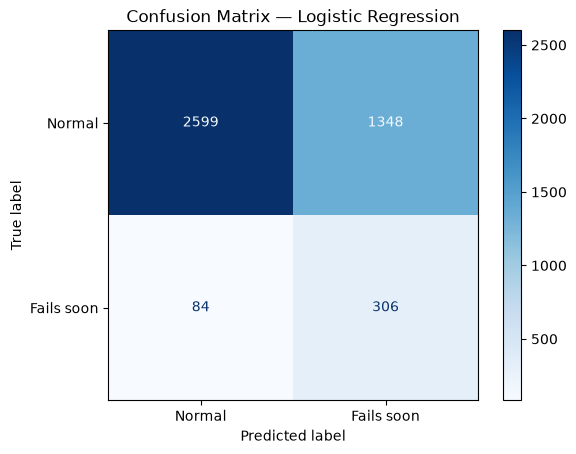

In [25]:
test["risk"]  = model.predict_proba(X_test)[:, 1]
test["alarm"] = (test["risk"] >= ALARM_THRESHOLD).astype(int)

print(classification_report(y_test, test["alarm"], target_names=["Normal", "Fails soon"]))

# Confusion matrix: rows = truth, columns = prediction
ConfusionMatrixDisplay.from_predictions(
    y_test, test["alarm"], display_labels=["Normal", "Fails soon"], cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.savefig("../images/05_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

### Feature importance
For a Random Forest, importance is how much each feature reduces impurity (Gini), averaged over all trees. The importances sum to 1.

This is shown for the Random Forest even if Logistic Regression was the best model.

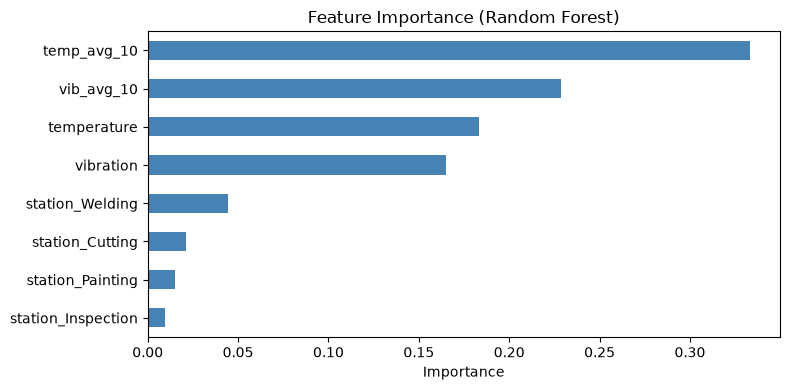

In [26]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

importance.plot(kind="barh", color="steelblue", figsize=(8, 4))
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../images/05_feature_importance.png", dpi=120)
plt.show()

### The alarm in action (Welding, test period)
Predicted risk over time, with the alarm threshold and the real breakdowns (red). Ideally the risk rises above the threshold shortly before each red line.

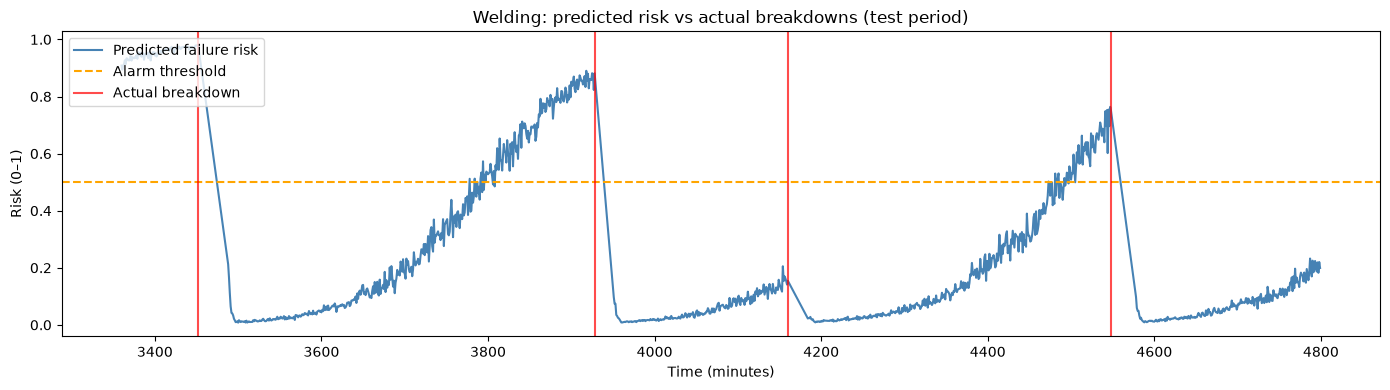

In [27]:
station = "Welding"
s = test[test["station"] == station]
f = failures[(failures["station"] == station) & (failures["failure_time"] >= split_time)]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(s["time"], s["risk"], color="steelblue", label="Predicted failure risk")
ax.axhline(ALARM_THRESHOLD, color="orange", linestyle="--", label="Alarm threshold")
for i, t in enumerate(f["failure_time"]):
    ax.axvline(t, color="red", alpha=0.7, label="Actual breakdown" if i == 0 else None)

ax.set_title(f"{station}: predicted risk vs actual breakdowns (test period)")
ax.set_xlabel("Time (minutes)")
ax.set_ylabel("Risk (0–1)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../images/05_risk_over_time.png", dpi=120)
plt.show()

### Business view: how much warning?
For each failure in the test period whose whole 30-min window lies inside the test data:
- **caught** if at least one alarm went off in the 30 min before it
- **warning** = $t_{fail} - t_{\text{first alarm}}$

$$\text{false alarm minutes/shift} = \frac{\#(\text{alarm} = 1 \text{ and fail\_soon} = 0)}{\text{test shifts}} \qquad \text{test shifts} = \frac{t_{max} - t_{split}}{480}$$

There's one row per running minute, so a row count is a count of minutes.

In [28]:
# Only failures whose full 30-minute window lies inside the test period
test_failures = failures[failures["failure_time"] >= split_time + HORIZON]

rows = []
for _, f in test_failures.iterrows():
    window = test[(test["station"] == f["station"])
                  & (test["time"] >= f["failure_time"] - HORIZON)
                  & (test["time"] <  f["failure_time"])]
    alarms = window[window["alarm"] == 1]
    caught = len(alarms) > 0
    rows.append({
        "station":      f["station"],
        "failure_time": round(f["failure_time"]),
        "caught":       caught,
        # warning = minutes between the FIRST alarm and the breakdown
        "warning_min":  round(f["failure_time"] - alarms["time"].min(), 1) if caught else 0,
    })
warnings = pd.DataFrame(rows)

test_shifts = (test["time"].max() - split_time) / 480
false_alarm_minutes = ((test["alarm"] == 1) & (test["fail_soon"] == 0)).sum()

print("🚨 EARLY WARNING PERFORMANCE")
print(f"  Breakdowns caught:     {warnings['caught'].sum()} of {len(warnings)} "
      f"({warnings['caught'].mean():.0%})")
print(f"  Avg warning time:      {warnings.loc[warnings['caught'], 'warning_min'].mean():.1f} minutes")
print(f"  False alarm minutes:   {false_alarm_minutes / test_shifts:.0f} per shift")
warnings

🚨 EARLY WARNING PERFORMANCE
  Breakdowns caught:     13 of 16 (81%)
  Avg warning time:      28.1 minutes
  False alarm minutes:   449 per shift


,station,failure_time,caught,warning_min
0,Inspection,3424,True,27.1
1,Welding,3452,True,29.3
2,Cutting,3542,True,29.5
3,Painting,3566,True,29.8
4,Painting,3908,True,29.8
5,Welding,3929,True,29.7
6,Painting,3963,False,0.0
7,Inspection,4010,True,17.0
8,Cutting,4049,True,29.9
9,Welding,4161,False,0.0


### Save the model
The model and the feature list are saved together, so the columns are in the right order when the model is used later.

In [29]:
os.makedirs("../models", exist_ok=True)
# Save the model AND the feature list together, so we know how to use it later
joblib.dump({"model": model, "features": FEATURES}, "../models/failure_predictor.joblib")
print("Saved models/failure_predictor.joblib 💾")

Saved models/failure_predictor.joblib 💾


### Use the model on new readings
Build a one-row DataFrame with all features set to 0, fill in the sensor values, set the station's one-hot column to 1, and return `predict_proba` for class 1.

In [30]:
def predict_failure_risk(station, temperature, vibration, temp_avg_10, vib_avg_10):
    """Return the probability (0–1) that this machine breaks within the next 30 minutes."""
    row = {col: 0 for col in FEATURES}                     # start with all zeros
    row.update(temperature=temperature, vibration=vibration,
               temp_avg_10=temp_avg_10, vib_avg_10=vib_avg_10)
    row[f"station_{station}"] = 1                          # switch on the right station column
    return model.predict_proba(pd.DataFrame([row]))[0, 1]

healthy = predict_failure_risk("Welding", temperature=66, vibration=1.6, temp_avg_10=66, vib_avg_10=1.6)
worn    = predict_failure_risk("Welding", temperature=84, vibration=4.5, temp_avg_10=83, vib_avg_10=4.4)
print(f"Healthy-looking welder: {healthy:.0%} risk")
print(f"Hot & shaky welder:     {worn:.0%} risk")

Healthy-looking welder: 1% risk
Hot & shaky welder:     89% risk


## 📝 Conclusions
- Best model: **Logistic Regression** (ROC AUC = **0.779**). The Random Forest was almost the same (0.772), so the simpler model is enough.
- It caught **81%** of breakdowns (13 of 16) with about **28 minutes** of warning on average. That is nearly the whole 30-minute window.
- Most important features: the **rolling averages**, temperature (0.33) and vibration (0.23), followed by the raw readings. The trend matters more than a single noisy reading. Station identity matters very little.
- Limitations:
  - Breakdowns are partly random, so some false alarms can't be avoided. Precision is about 19%, which means about 449 false-alarm minutes per shift across the 4 machines.
  - In maintenance, a false alarm (a quick check) is much cheaper than a breakdown (a 20–40 min stop).
  - A higher alarm threshold would reduce false alarms but catch fewer breakdowns.